# 1. Import Libraries

In [48]:
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

# 2. Load Data

In [3]:
data_path = Path("data/staging/08_integrated/flights_airports_weather_2024.parquet")

if not data_path.exists():
    data_path = Path.cwd().parent / data_path

if not data_path.exists():
    raise FileNotFoundError(f"Integrated data file not found: {data_path}")

flights = pd.read_parquet(data_path)

print(f"Loaded {len(flights):,} rows and {len(flights.columns):,} columns")
print(f"Data source: {data_path}")
pd.set_option('display.max_columns', None)
flights.head()

Loaded 1,929,930 rows and 34 columns
Data source: e:\COMP333-FlightDelayPrediction\data\staging\08_integrated\flights_airports_weather_2024.parquet


,FlightDate,DepTime,OriginAirportSeqID,OriginCityName,OriginStateName,DestAirportSeqID,DestCityName,DestStateName,DepDel15,WeatherDelay,AirportCountryName,AirportStateName,AirportName,AirportCityName,AirportLatitude,AirportLongitude,AirportUTCOffset,WeatherStationID,AirportWeatherStationDistanceKm,WeatherStationPriority,WeatherStationLatitude,WeatherStationLongitude,STATION,DATE,temperature,wind_speed,visibility,dew_point_temperature,station_level_pressure,wind_gust,precipitation,wet_bulb_temperature,relative_humidity,WeatherObservationLocalDateTime
0,2024-01-14,1203,1393008,"Chicago, IL",Illinois,1043106,"Asheville, NC",North Carolina,1.00,58.00,United States,Illinois,Chicago O'Hare International,"Chicago, IL",41.97694444,-87.90805556,-0600,USW00094846,2.691956,2,41.9603,-87.9317,USW00094846,2024-01-14T18:51:00,-21.7,9.3,16.093,-26.1,997.1,13.9,0.0,-22.1,68,2024-01-14T12:51:00
1,2024-01-14,1415,1393008,"Chicago, IL",Illinois,1473004,"Louisville, KY",Kentucky,0.00,,United States,Illinois,Chicago O'Hare International,"Chicago, IL",41.97694444,-87.90805556,-0600,USW00094846,2.691956,2,41.9603,-87.9317,USW00094846,2024-01-14T20:51:00,-21.1,6.2,16.093,-25.6,997.1,10.3,0.0,-21.6,67,2024-01-14T14:51:00
2,2024-01-14,1132,1393008,"Chicago, IL",Illinois,1452401,"Richmond, VA",Virginia,1.00,22.00,United States,Illinois,Chicago O'Hare International,"Chicago, IL",41.97694444,-87.90805556,-0600,USW00094846,2.691956,2,41.9603,-87.9317,USW00094846,2024-01-14T17:51:00,-22.2,7.7,16.093,-26.7,996.8,12.4,0.0,-22.7,67,2024-01-14T11:51:00
3,2024-01-14,0945,1393008,"Chicago, IL",Illinois,1126702,"Dayton, OH",Ohio,1.00,,United States,Illinois,Chicago O'Hare International,"Chicago, IL",41.97694444,-87.90805556,-0600,USW00094846,2.691956,2,41.9603,-87.9317,USW00094846,2024-01-14T15:51:00,-22.8,6.7,16.093,-27.2,995.8,11.8,0.0,-23.2,67,2024-01-14T09:51:00
4,2024-01-14,1238,1393008,"Chicago, IL",Illinois,1177502,"Sioux Falls, SD",South Dakota,0.00,,United States,Illinois,Chicago O'Hare International,"Chicago, IL",41.97694444,-87.90805556,-0600,USW00094846,2.691956,2,41.9603,-87.9317,USW00094846,2024-01-14T18:51:00,-21.7,9.3,16.093,-26.1,997.1,13.9,0.0,-22.1,68,2024-01-14T12:51:00


## Prepare data for the torch api

We need to prepare the data so that it can be passed to the Pytorch neural network.

- Convert numerical columns to their numeric type and use OrdinalEncoder to for the categorical columns.

- Convert Datetime columns to a numeric type.

- Remove the column `WeatherDelay` since it not the target feature and it kinda cheating.

- Set NaN value to 0.

- This will represent the dataset before any preparation.

In [32]:
data_raw = flights.copy()
data_raw = data_raw.drop(columns='WeatherDelay')

In [34]:
numerical_columns = [
    'DepTime', 'DepDel15', 'AirportLatitude', 'AirportLongitude', 
    'AirportUTCOffset', 'AirportWeatherStationDistanceKm', 'WeatherStationPriority',
    'WeatherStationLatitude', 'WeatherStationLongitude', 'temperature', 'wind_speed',
    'visibility', 'dew_point_temperature', 'station_level_pressure', 'wind_gust',
    'precipitation', 'wet_bulb_temperature', 'relative_humidity']

In [35]:
data_raw[numerical_columns] = data_raw[numerical_columns].apply(pd.to_numeric, errors='coerce')

In [37]:
date_columns = ['FlightDate', 'DATE', 'WeatherObservationLocalDateTime']

In [38]:
data_raw[date_columns] = data_raw[date_columns].apply(
    lambda col: pd.to_datetime(col, errors='coerce').dt.day_of_year
)

In [41]:
categorical_columns = [
    'OriginAirportSeqID', 'OriginCityName', 'OriginStateName', 'DestAirportSeqID', 'DestCityName',
    'DestStateName', 'AirportCountryName', 'AirportStateName', 'AirportName', 'AirportCityName',
    'WeatherStationID', 'STATION'
    ]

In [44]:
ordinal_encoder = OrdinalEncoder()
data_raw[categorical_columns] = ordinal_encoder.fit_transform(data_raw[categorical_columns])

In [70]:
data_raw = data_raw.fillna(0)

# 3. Train Neural Network

In [73]:
target = "DepDel15"
X = data_raw.drop(columns=[target])
y = data_raw[target]

In [75]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [76]:
X_train = X_train.to_numpy(dtype=np.float32)
X_test = X_test.to_numpy(dtype=np.float32)

y_train = y_train.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)

# Convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

In [77]:
train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=True
)

In [87]:
test_dataset = TensorDataset(X_test, y_test)
test_loader = DataLoader(
    test_dataset,
    batch_size=1024,
    shuffle=False
)

In [78]:
class NeuralNetwork(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

In [81]:
model_raw = NeuralNetwork(X_train.shape[1])

positive = y_train.sum()
negative = len(y_train) - positive

pos_weight = negative / positive

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.Adam(
    model_raw.parameters(),
    lr=0.001
)

In [ ]:
def train_model(model, train_loader, criterion, optimizer, epochs=200):

    history = []

    for epoch in range(epochs):

        model.train()
        total_loss = 0

        for X_batch, y_batch in train_loader:

            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        history.append(avg_loss)

        print(f"Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.4f}")

    return model, history

In [84]:
model_raw, history_raw = train_model(
    model_raw,
    train_loader,
    criterion,
    optimizer
)

Epoch [1/20], Loss: 1.5595
Epoch [2/20], Loss: 1.2329
Epoch [3/20], Loss: 1.2154
Epoch [4/20], Loss: 1.2070
Epoch [5/20], Loss: 1.2033
Epoch [6/20], Loss: 1.1971
Epoch [7/20], Loss: 1.1940
Epoch [8/20], Loss: 1.1907
Epoch [9/20], Loss: 1.1883
Epoch [10/20], Loss: 1.1859
Epoch [11/20], Loss: 1.1847
Epoch [12/20], Loss: 1.1837
Epoch [13/20], Loss: 1.1839
Epoch [14/20], Loss: 1.1823
Epoch [15/20], Loss: 1.1815
Epoch [16/20], Loss: 1.1811
Epoch [17/20], Loss: 1.1808
Epoch [18/20], Loss: 1.1799
Epoch [19/20], Loss: 1.1798
Epoch [20/20], Loss: 1.1799


In [90]:
def evaluate_model(model, test_loader):

    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():

        for X_batch, y_batch in test_loader:

            logits = model(X_batch)

            probabilities = torch.sigmoid(logits)

            predictions = (probabilities >= 0.5).int()

            y_true.extend(y_batch.cpu().numpy())
            y_pred.extend(predictions.cpu().numpy())

    f1_binary = f1_score(y_true, y_pred, average="binary")
    f1_macro = f1_score(y_true, y_pred, average="macro")

    return f1_binary, f1_macro

In [91]:
f1_binary_raw, f1_macro_raw = evaluate_model(model_raw, test_loader)

print(f"Raw Dataset Binary F1 Score: {f1_binary_raw:.4f}")
print(f"Raw Dataset Macro F1 Score: {f1_macro_raw:.4f}")

Raw Dataset Binary F1 Score: 0.1967
Raw Dataset Macro F1 Score: 0.4986


# 4. Clean and Train Again

- Remove rows that do not contain a weather observation.
- Remove columns that have too many '' values.
- Drop remaining rows containg '' values.

In [ ]:
flights = flights.drop(columns='WeatherDelay')

In [99]:
data_cleaned = flights.copy()

In [101]:
data_cleaned = data_cleaned.dropna()

In [102]:
data_cleaned = data_cleaned.drop(columns=['wind_gust', 'wet_bulb_temperature'])

In [104]:
numerical_columns = [
    'DepTime', 'DepDel15', 'AirportLatitude', 'AirportLongitude', 
    'AirportUTCOffset', 'AirportWeatherStationDistanceKm', 'WeatherStationPriority',
    'WeatherStationLatitude', 'WeatherStationLongitude', 'temperature', 'wind_speed',
    'visibility', 'dew_point_temperature', 'station_level_pressure',
    'precipitation', 'relative_humidity']
date_columns = ['FlightDate', 'DATE', 'WeatherObservationLocalDateTime']
categorical_columns = [
    'OriginAirportSeqID', 'OriginCityName', 'OriginStateName', 'DestAirportSeqID', 'DestCityName',
    'DestStateName', 'AirportCountryName', 'AirportStateName', 'AirportName', 'AirportCityName',
    'WeatherStationID', 'STATION'
    ]

In [105]:
data_cleaned[numerical_columns] = data_cleaned[numerical_columns].apply(pd.to_numeric, errors='coerce')
data_cleaned[date_columns] = data_cleaned[date_columns].apply(
    lambda col: pd.to_datetime(col, errors='coerce').dt.day_of_year
)
data_cleaned[categorical_columns] = ordinal_encoder.fit_transform(data_cleaned[categorical_columns])

In [107]:
data_cleaned = data_cleaned.dropna()

In [110]:
target = "DepDel15"
X = data_cleaned.drop(columns=[target])
y = data_cleaned[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train = X_train.to_numpy(dtype=np.float32)
X_test = X_test.to_numpy(dtype=np.float32)

y_train = y_train.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)

# Convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)
train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=True
)
test_dataset = TensorDataset(X_test, y_test)
test_loader = DataLoader(
    test_dataset,
    batch_size=1024,
    shuffle=False
)

model_cleaned = NeuralNetwork(X_train.shape[1])

positive = y_train.sum()
negative = len(y_train) - positive

pos_weight = negative / positive

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.Adam(
    model_cleaned.parameters(),
    lr=0.001
)

In [111]:
model_cleaned, history_cleaned = train_model(
    model_cleaned,
    train_loader,
    criterion,
    optimizer
)

Epoch [1/20], Loss: 1.4690
Epoch [2/20], Loss: 1.2326
Epoch [3/20], Loss: 1.2142
Epoch [4/20], Loss: 1.2043
Epoch [5/20], Loss: 1.1997
Epoch [6/20], Loss: 1.1975
Epoch [7/20], Loss: 1.1955
Epoch [8/20], Loss: 1.1941
Epoch [9/20], Loss: 1.1928
Epoch [10/20], Loss: 1.1910
Epoch [11/20], Loss: 1.1888
Epoch [12/20], Loss: 1.1868
Epoch [13/20], Loss: 1.1860
Epoch [14/20], Loss: 1.1854
Epoch [15/20], Loss: 1.1834
Epoch [16/20], Loss: 1.1836
Epoch [17/20], Loss: 1.1831
Epoch [18/20], Loss: 1.1819
Epoch [19/20], Loss: 1.1826
Epoch [20/20], Loss: 1.1819


In [ ]:
f1_binary_cleaned, f1_macro_cleaned = evaluate_model(model_cleaned, test_loader)

print(f"Cleaned Dataset Binary F1 Score: {f1_binary_cleaned:.4f}")
print(f"Cleaned Dataset Macro F1 Score: {f1_macro_cleaned:.4f}")

Raw Dataset Binary F1 Score: 0.2095
Raw Dataset Macro F1 Score: 0.5253


# 5. Transform and train model

- Use Standard Scaler on Numerical Values.
- Transform DateTime Features into Multiple Columns 'Month', 'Day', 'Day_of_Week'.
- Apply OneHotEncoding to Categorical Features.

In [113]:
flights = flights.drop(columns=['wind_gust', 'wet_bulb_temperature'])

In [140]:
data_transformed = flights.copy()

In [120]:
def clean(data: pd.DataFrame) -> pd.DataFrame:
    data = data.dropna()
    data[numerical_columns] = data[numerical_columns].apply(pd.to_numeric, errors='coerce')
    data = data.dropna()
    return data

In [141]:
data_transformed = clean(data_transformed)

In [128]:
def encode_datetime(df, date_columns):
    df = df.copy()

    for col in date_columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

        df[f'{col}_month'] = df[col].dt.month
        df[f'{col}_day'] = df[col].dt.day
        df[f'{col}_day_of_week'] = df[col].dt.day_of_week

    df = df.drop(columns=date_columns)

    return df

In [142]:
data_transformed = encode_datetime(data_transformed, date_columns)

In [133]:
numerical_columns.remove('DepDel15')

In [130]:
new_date_columns = [
    'FlightDate_month', 'FlightDate_day', 'FlightDate_day_of_week',
    'DATE_month', 'DATE_day', 'DATE_day_of_week', 
    'WeatherObservationLocalDateTime_month', 'WeatherObservationLocalDateTime_day', 
    'WeatherObservationLocalDateTime_day_of_week']
categorical_columns = categorical_columns + new_date_columns

In [143]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_columns)
    ],
    remainder='drop'
)

In [144]:
target = "DepDel15"
X = data_transformed.drop(columns=[target])
y = data_transformed[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = y_train.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)

y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)
train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=True
)
test_dataset = TensorDataset(X_test, y_test)
test_loader = DataLoader(
    test_dataset,
    batch_size=1024,
    shuffle=False
)

model_transformed = NeuralNetwork(X_train.shape[1])

positive = y_train.sum()
negative = len(y_train) - positive

pos_weight = negative / positive

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.Adam(
    model_transformed.parameters(),
    lr=0.001
)

In [145]:
model_transformed, history_transformed = train_model(
    model_transformed,
    train_loader,
    criterion,
    optimizer
)

Epoch [1/20], Loss: 1.1775
Epoch [2/20], Loss: 1.1339
Epoch [3/20], Loss: 1.1172
Epoch [4/20], Loss: 1.1080
Epoch [5/20], Loss: 1.1026
Epoch [6/20], Loss: 1.0976
Epoch [7/20], Loss: 1.0932
Epoch [8/20], Loss: 1.0893
Epoch [9/20], Loss: 1.0857
Epoch [10/20], Loss: 1.0837
Epoch [11/20], Loss: 1.0806
Epoch [12/20], Loss: 1.0784
Epoch [13/20], Loss: 1.0767
Epoch [14/20], Loss: 1.0738
Epoch [15/20], Loss: 1.0723
Epoch [16/20], Loss: 1.0693
Epoch [17/20], Loss: 1.0683
Epoch [18/20], Loss: 1.0665
Epoch [19/20], Loss: 1.0650
Epoch [20/20], Loss: 1.0636


In [ ]:
f1_binary_transformed, f1_macro_transformed = evaluate_model(model_transformed, test_loader)

print(f"Transformed Dataset Binary F1 Score: {f1_binary_transformed:.4f}")
print(f"Transformed Dataset Macro F1 Score: {f1_macro_transformed:.4f}")

Raw Dataset Binary F1 Score: 0.2299
Raw Dataset Macro F1 Score: 0.5255


# 6. Feature Selection and Train Model

- Remove Columns that makes no sense
- Remove Columns that are highly correlated

In [147]:
flights.head()

,FlightDate,DepTime,OriginAirportSeqID,OriginCityName,OriginStateName,DestAirportSeqID,DestCityName,DestStateName,DepDel15,AirportCountryName,AirportStateName,AirportName,AirportCityName,AirportLatitude,AirportLongitude,AirportUTCOffset,WeatherStationID,AirportWeatherStationDistanceKm,WeatherStationPriority,WeatherStationLatitude,WeatherStationLongitude,STATION,DATE,temperature,wind_speed,visibility,dew_point_temperature,station_level_pressure,precipitation,relative_humidity,WeatherObservationLocalDateTime
0,2024-01-14,1203,1393008,"Chicago, IL",Illinois,1043106,"Asheville, NC",North Carolina,1.00,United States,Illinois,Chicago O'Hare International,"Chicago, IL",41.97694444,-87.90805556,-0600,USW00094846,2.691956,2,41.9603,-87.9317,USW00094846,2024-01-14T18:51:00,-21.7,9.3,16.093,-26.1,997.1,0.0,68,2024-01-14T12:51:00
1,2024-01-14,1415,1393008,"Chicago, IL",Illinois,1473004,"Louisville, KY",Kentucky,0.00,United States,Illinois,Chicago O'Hare International,"Chicago, IL",41.97694444,-87.90805556,-0600,USW00094846,2.691956,2,41.9603,-87.9317,USW00094846,2024-01-14T20:51:00,-21.1,6.2,16.093,-25.6,997.1,0.0,67,2024-01-14T14:51:00
2,2024-01-14,1132,1393008,"Chicago, IL",Illinois,1452401,"Richmond, VA",Virginia,1.00,United States,Illinois,Chicago O'Hare International,"Chicago, IL",41.97694444,-87.90805556,-0600,USW00094846,2.691956,2,41.9603,-87.9317,USW00094846,2024-01-14T17:51:00,-22.2,7.7,16.093,-26.7,996.8,0.0,67,2024-01-14T11:51:00
3,2024-01-14,0945,1393008,"Chicago, IL",Illinois,1126702,"Dayton, OH",Ohio,1.00,United States,Illinois,Chicago O'Hare International,"Chicago, IL",41.97694444,-87.90805556,-0600,USW00094846,2.691956,2,41.9603,-87.9317,USW00094846,2024-01-14T15:51:00,-22.8,6.7,16.093,-27.2,995.8,0.0,67,2024-01-14T09:51:00
4,2024-01-14,1238,1393008,"Chicago, IL",Illinois,1177502,"Sioux Falls, SD",South Dakota,0.00,United States,Illinois,Chicago O'Hare International,"Chicago, IL",41.97694444,-87.90805556,-0600,USW00094846,2.691956,2,41.9603,-87.9317,USW00094846,2024-01-14T18:51:00,-21.7,9.3,16.093,-26.1,997.1,0.0,68,2024-01-14T12:51:00


In [169]:
columns_to_remove = [
    'OriginCityName', 'OriginStateName', 'DestCityName', 'DestStateName', 'AirportCountryName',
    'AirportStateName', 'AirportCityName', 'AirportLatitude', 'AirportLongitude', 'AirportUTCOffset',
    'WeatherStationID', 'AirportWeatherStationDistanceKm', 'WeatherStationPriority', 'WeatherStationLatitude',
    'WeatherStationLongitude', 'STATION', 'DATE', 'WeatherObservationLocalDateTime', 'AirportName'
    ]

In [170]:
data_extracted = flights.copy()

In [171]:
data_extracted = data_extracted.drop(columns=columns_to_remove)

In [172]:
data_extracted.head()

,FlightDate,DepTime,OriginAirportSeqID,DestAirportSeqID,DepDel15,temperature,wind_speed,visibility,dew_point_temperature,station_level_pressure,precipitation,relative_humidity
0,2024-01-14,1203,1393008,1043106,1.00,-21.7,9.3,16.093,-26.1,997.1,0.0,68
1,2024-01-14,1415,1393008,1473004,0.00,-21.1,6.2,16.093,-25.6,997.1,0.0,67
2,2024-01-14,1132,1393008,1452401,1.00,-22.2,7.7,16.093,-26.7,996.8,0.0,67
3,2024-01-14,0945,1393008,1126702,1.00,-22.8,6.7,16.093,-27.2,995.8,0.0,67
4,2024-01-14,1238,1393008,1177502,0.00,-21.7,9.3,16.093,-26.1,997.1,0.0,68


In [177]:
numerical_columns = [
    'DepTime', 'temperature', 'wind_speed', 'visibility',
    'dew_point_temperature', 'station_level_pressure',
    'precipitation', 'relative_humidity', 'DepDel15'
    ]

In [174]:
data_extracted = clean(data_extracted)

In [178]:
numerical_columns.remove('DepDel15')

In [179]:
data_extracted = encode_datetime(data_extracted, ['FlightDate'])

In [180]:
data_extracted.head()

,DepTime,OriginAirportSeqID,DestAirportSeqID,DepDel15,temperature,wind_speed,visibility,dew_point_temperature,station_level_pressure,precipitation,relative_humidity,FlightDate_month,FlightDate_day,FlightDate_day_of_week
0,1203,1393008,1043106,1.0,-21.7,9.3,16.093,-26.1,997.1,0.0,68.0,1,14,6
1,1415,1393008,1473004,0.0,-21.1,6.2,16.093,-25.6,997.1,0.0,67.0,1,14,6
2,1132,1393008,1452401,1.0,-22.2,7.7,16.093,-26.7,996.8,0.0,67.0,1,14,6
3,945,1393008,1126702,1.0,-22.8,6.7,16.093,-27.2,995.8,0.0,67.0,1,14,6
4,1238,1393008,1177502,0.0,-21.7,9.3,16.093,-26.1,997.1,0.0,68.0,1,14,6


In [181]:
categorical_columns = [
    'OriginAirportSeqID', 'DestAirportSeqID', 'FlightDate_month',
    'FlightDate_day', 'FlightDate_day_of_week'
    ]

In [183]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_columns)
    ],
    remainder='drop'
)

In [184]:
target = "DepDel15"
X = data_extracted.drop(columns=[target])
y = data_extracted[target]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = y_train.to_numpy(dtype=np.float32)
y_test = y_test.to_numpy(dtype=np.float32)

y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)
train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=1024,
    shuffle=True
)
test_dataset = TensorDataset(X_test, y_test)
test_loader = DataLoader(
    test_dataset,
    batch_size=1024,
    shuffle=False
)

model_extracted = NeuralNetwork(X_train.shape[1])

positive = y_train.sum()
negative = len(y_train) - positive

pos_weight = negative / positive

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

optimizer = torch.optim.Adam(
    model_extracted.parameters(),
    lr=0.001
)

In [185]:
model_extracted, history_extracted = train_model(
    model_extracted,
    train_loader,
    criterion,
    optimizer
)

Epoch [1/20], Loss: 1.1785
Epoch [2/20], Loss: 1.1334
Epoch [3/20], Loss: 1.1193
Epoch [4/20], Loss: 1.1106
Epoch [5/20], Loss: 1.1035
Epoch [6/20], Loss: 1.0983
Epoch [7/20], Loss: 1.0940
Epoch [8/20], Loss: 1.0896
Epoch [9/20], Loss: 1.0853
Epoch [10/20], Loss: 1.0831
Epoch [11/20], Loss: 1.0803
Epoch [12/20], Loss: 1.0779
Epoch [13/20], Loss: 1.0745
Epoch [14/20], Loss: 1.0731
Epoch [15/20], Loss: 1.0708
Epoch [16/20], Loss: 1.0694
Epoch [17/20], Loss: 1.0674
Epoch [18/20], Loss: 1.0654
Epoch [19/20], Loss: 1.0635
Epoch [20/20], Loss: 1.0622


In [ ]:
f1_binary_extracted, f1_macro_extracted = evaluate_model(model_extracted, test_loader)

print(f"Feature Extracted Dataset Binary F1 Score: {f1_binary_extracted:.4f}")
print(f"Feature Extracted Dataset Macro F1 Score: {f1_macro_extracted:.4f}")

Raw Dataset Binary F1 Score: 0.2214
Raw Dataset Macro F1 Score: 0.5091


# 7. Compare

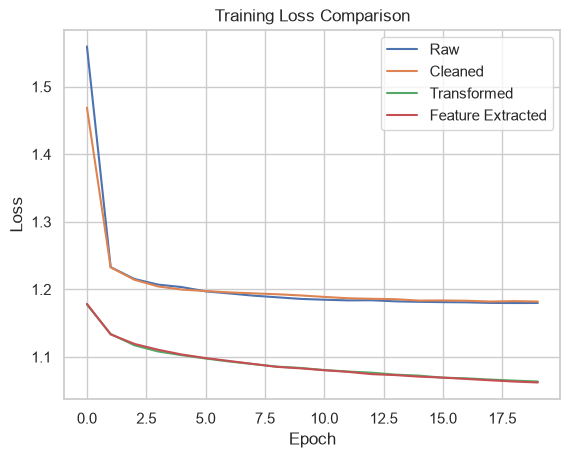

In [187]:
plt.plot(history_raw, label='Raw')
plt.plot(history_cleaned, label='Cleaned')
plt.plot(history_transformed, label='Transformed')
plt.plot(history_extracted, label='Feature Extracted')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss Comparison')
plt.legend()
plt.show()

In [192]:
binary_scores = {
    "Data preparation step": [
        "Cleaning",
        "Transformation",
        "Feature selection"
    ],
    "Baseline score": [
        f1_binary_raw,
        f1_binary_raw,
        f1_binary_raw
    ],
    "New score": [
        f1_binary_cleaned,
        f1_binary_transformed,
        f1_binary_extracted
    ]
}

df_binary = pd.DataFrame(binary_scores)

df_binary["Delta (New - Baseline)"] = (
    df_binary["New score"] - df_binary["Baseline score"]
)

display(df_binary.round(4))

,Data preparation step,Baseline score,New score,Delta (New - Baseline)
0,Cleaning,0.1967,0.2095,0.0127
1,Transformation,0.1967,0.2299,0.0332
2,Feature selection,0.1967,0.2214,0.0247


In [191]:
macro_scores = {
    "Data preparation step": [
        "Cleaning",
        "Transformation",
        "Feature selection"
    ],
    "Baseline score": [
        f1_macro_raw,
        f1_macro_raw,
        f1_macro_raw
    ],
    "New score": [
        f1_macro_cleaned,
        f1_macro_transformed,
        f1_macro_extracted
    ]
}

df_macro = pd.DataFrame(macro_scores)

df_macro["Delta (New - Baseline)"] = (
    df_macro["New score"] - df_macro["Baseline score"]
)

display(df_macro.round(4))

,Data preparation step,Baseline score,New score,Delta (New - Baseline)
0,Cleaning,0.4986,0.5253,0.0268
1,Transformation,0.4986,0.5255,0.0269
2,Feature selection,0.4986,0.5091,0.0105
